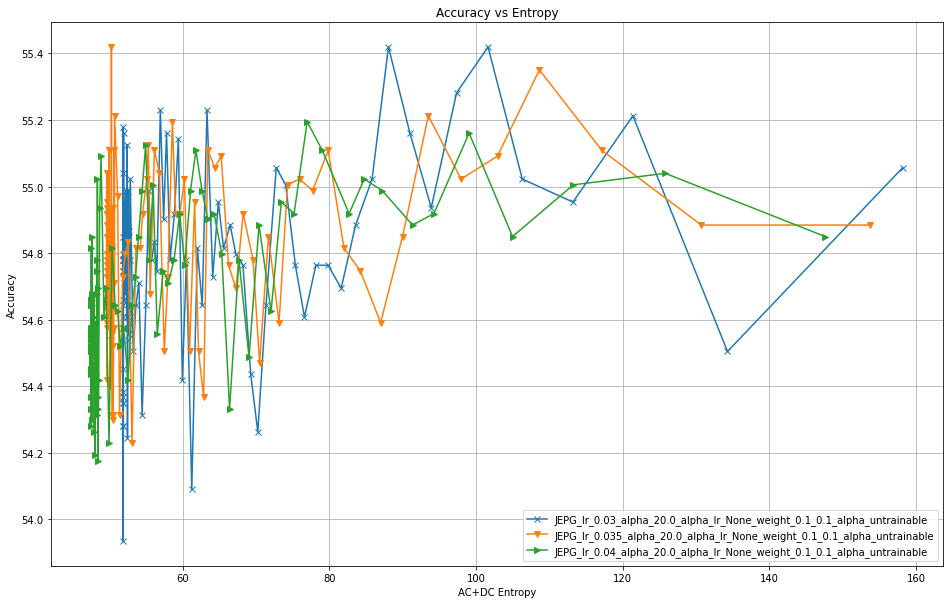

In [11]:
import matplotlib.pyplot as plt
import os


def read_file(file_path):
    data = []
    with open(file_path, 'r') as file:
        for line in file:
            parts = line.split()
            if len(parts) == 16:
                row = list(map(float, parts))
                data.append(row)
    return data


def plot_data(file_path, marker, label):
    data = read_file(file_path)
    y_values = [row[2] for row in data] # test acc
    x_values = [row[6] + row[7] + row[8] + row[9] for row in data] # entropy
    # x_values = [row[4] for row in data] # test loss
    plt.plot(x_values, y_values, marker=marker, label=label)


def plot_data_average(base_path):
    total_y_sums = []
    total_x_sums = []
    
    file_count = 0
    for trial_folder in os.listdir(base_path):
        folder_path = os.path.join(base_path, trial_folder)
        if os.path.isdir(folder_path):  # 确保是文件夹
            log_file_path = os.path.join(folder_path, 'logs.txt')
            print(log_file_path)
            if os.path.exists(log_file_path):
                data = read_file(log_file_path)
                y_values = [row[2] for row in data] # test acc
                x_values = [row[6] + row[7] + row[8] + row[9] for row in data] # entropy
                print(len(x_values))
                if not total_y_sums:
                    total_y_sums = y_values
                    total_x_sums = x_values
                else:
                    total_y_sums = [sum(x) for x in zip(total_y_sums, y_values)]
                    total_x_sums = [sum(x) for x in zip(total_x_sums, x_values)]
                file_count += 1
    if file_count > 0:
        average_y = [y / file_count for y in total_y_sums]
        average_x = [x / file_count for x in total_x_sums]
    
    print(len(average_x))
    plt.plot(average_x, average_y, marker="^", label='JEPG_lr_0.01_alpha_100.0')


plt.figure(figsize=(16, 10))

base_path = './save/CUB200/resnet18'

file_name_1 = "JEPG_lr_0.015_alpha_20.0_alpha_lr_None_weight_0.1_0.1_alpha_untrainable"
file_name_2 = "JEPG_lr_0.02_alpha_20.0_alpha_lr_None_weight_0.1_0.1_alpha_untrainable"
file_name_3 = "JEPG_lr_0.025_alpha_20.0_alpha_lr_None_weight_0.1_0.1_alpha_untrainable"
file_name_4 = "JEPG_lr_0.03_alpha_20.0_alpha_lr_None_weight_0.1_0.1_alpha_untrainable"
file_name_5 = "JEPG_lr_0.035_alpha_20.0_alpha_lr_None_weight_0.1_0.1_alpha_untrainable"
file_name_6 = "JEPG_lr_0.04_alpha_20.0_alpha_lr_None_weight_0.1_0.1_alpha_untrainable"

# plot_data(os.path.join(os.path.join(base_path, file_name_1), "trial_1/logs.txt"), 'o', file_name_1)
# plot_data(os.path.join(os.path.join(base_path, file_name_2), "trial_1/logs.txt"), '^', file_name_2)
# plot_data(os.path.join(os.path.join(base_path, file_name_3), "trial_1/logs.txt"), '.', file_name_3)
plot_data(os.path.join(os.path.join(base_path, file_name_4), "trial_1/logs.txt"), 'x', file_name_4)
plot_data(os.path.join(os.path.join(base_path, file_name_5), "trial_1/logs.txt"), 'v', file_name_5)
plot_data(os.path.join(os.path.join(base_path, file_name_6), "trial_1/logs.txt"), '>', file_name_6)

# plot_data_average('./save/CUB200/resnet18/JEPG_lr_0.04_alpha_2.0_alpha_lr_None_weight_0.5_0.5_alpha_untrainable')

plt.xlabel('AC+DC Entropy')
plt.ylabel('Accuracy')
plt.title('Accuracy vs Entropy')
plt.legend()
plt.grid(True)
plt.show()
    

100


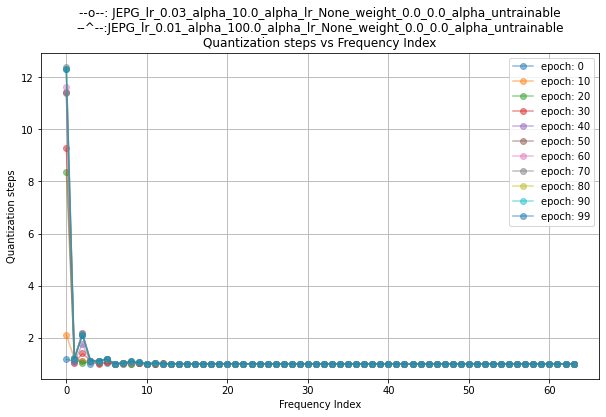

In [6]:
import numpy as np
import matplotlib.pyplot as plt


def zigzag(matrix):
    zigzag = np.array([[0, 1, 5, 6, 14, 15, 27, 28],
                        [2, 4, 7, 13, 16, 26, 29, 42],
                        [3, 8, 12, 17, 25, 30, 41, 43],
                        [9, 11, 18, 24, 31, 40, 44, 53],
                        [10, 19, 23, 32, 39, 45, 52, 54],
                        [20, 22, 33, 38, 46, 51, 55, 60],
                        [21, 34, 37, 47, 50, 56, 59, 61],
                        [35, 36, 48, 49, 57, 58, 62, 63]])

    # Get the shape of the matrix
    matrix_size = np.shape(matrix)
    
    # Calculate the size of the vector
    vector_size = np.shape(zigzag)
    
    # Check if the matrix size matches the vector size
    if matrix_size != vector_size:
        raise ValueError("The matrix size does not match the vector size.")

    # Create an empty vector to store the values
    vector = np.zeros(matrix_size[0] * matrix_size[1])

    # Iterate over each element in the matrix and place it in the corresponding position in the vector
    for i in range(matrix_size[0]):
        for j in range(matrix_size[1]):
            index = zigzag[i, j]
            vector[index] = matrix[i, j]

    return vector


def plot_q_table(filepaths, marker):
    with open(filepaths, "r") as file:
        lines = file.read()

    q_tables = lines.split("\n\n")[:-1]
    print(len(q_tables))
    
    for epoch, q_table in enumerate(q_tables):
        if epoch % 10 != 0 and epoch != 99:
            continue
        matrix = np.array([list(map(float, row.split(","))) for row in q_table.split("\n")])
        matrix = zigzag(matrix).flatten()
        plt.plot(matrix, marker=marker, label=f'epoch: {epoch}', alpha=0.5)


base_path = './save/CUB200/resnet18'

file_name_1 = "JEPG_lr_0.03_alpha_10.0_alpha_lr_None_weight_0.0_0.0_alpha_untrainable"
file_name_2 = "JEPG_lr_0.01_alpha_100.0_alpha_lr_None_weight_0.0_0.0_alpha_untrainable"
    
file_path_1 = os.path.join(base_path, file_name_1)
file_path_2 = os.path.join(base_path, file_name_2)

logs_path_1 = os.path.join(file_path_1, "trial_1/Q_tables/chrom_q_table.txt")
logs_path_2 = os.path.join(file_path_2, "trial_1/Q_tables/chrom_q_table.txt")


plt.figure(figsize=(10, 6))

plot_q_table(logs_path_1, "o")
# plot_q_table(logs_path_2, "^")

plt.xlabel('Frequency Index')
plt.ylabel('Quantization steps')
plt.title('--o--: ' + file_name_1 + '\n--^--:' + file_name_2 + '\nQuantization steps vs Frequency Index')
plt.legend()
plt.grid(True)
plt.show()

In [9]:
import torch

loaded_tensor = torch.load('./save/CUB200/resnet18/JEPG_lr_0.025_alpha_20.0_alpha_lr_None_weight_0.0_0.0_alpha_untrainable/trial_1/Q_tables/q_table_epoch_100.pt')
print(loaded_tensor)


tensor([[[9.9926, 1.9470, 2.1682, 1.0628, 1.0534, 1.0181, 1.0158, 1.0117],
         [1.0043, 1.0280, 1.0281, 1.2054, 1.0970, 1.0226, 1.0011, 1.0085],
         [1.0306, 1.2751, 1.1109, 1.2525, 1.0539, 1.0416, 1.0022, 1.0089],
         [1.3575, 1.0420, 1.1247, 1.0350, 1.0069, 1.0008, 1.0070, 1.0025],
         [1.0005, 1.1247, 1.1288, 1.0879, 1.0056, 1.0015, 1.0002, 1.0007],
         [1.0770, 1.0008, 1.0293, 1.0195, 1.0082, 1.0059, 1.0001, 1.0013],
         [1.0079, 1.0186, 1.0015, 1.0027, 1.0033, 1.0010, 1.0005, 1.0002],
         [1.0238, 1.0148, 1.0017, 1.0017, 1.0009, 1.0030, 1.0014, 1.0005]],

        [[1.8106, 1.4756, 1.0417, 1.0452, 1.0197, 1.0040, 1.0011, 1.0025],
         [1.7634, 1.1015, 1.0623, 1.0009, 1.0040, 1.0025, 1.0023, 1.0002],
         [1.6592, 1.0348, 1.0767, 1.0152, 1.0021, 1.0004, 1.0016, 1.0001],
         [1.1539, 1.0099, 1.0042, 1.0029, 1.0016, 1.0000, 1.0005, 1.0018],
         [1.0156, 1.0208, 1.0089, 1.0047, 1.0008, 1.0004, 1.0012, 1.0002],
         [1.0000, 1.003